# Ćwiczenie 5 — Landsat 8 Collection 2 Level-2 z Google Earth Engine

**Cel:** wyszukać scenę Landsat 8 dla Krakowa, zastosować poprawne skalowanie reflektancji, usunąć chmury i cienie na podstawie `QA_PIXEL`, obliczyć NDVI, wyświetlić RGB i zapisać wyniki jako GeoTIFF. Następnie odczytać je lokalnie przez `rasterio`.

Dane: **USGS Landsat 8 Level 2, Collection 2, Tier 1** (`LANDSAT/LC08/C02/T1_L2`); rozdzielczość kanałów SR: **30 m**. Projekt GEE: `ee-beatastark`.

**Uwaga:** wybieramy jedną scenę, a nie kompozyt czasowy. Pierwszy wybór to najmniejsze `CLOUD_COVER` w sierpniu 2026. Nie jest gwarantowane, że dostępna będzie dokładnie scena z 27.08.2026.

## 1. Importy i konfiguracja

Biblioteki zainstalowane wcześniej w `jupyter_base` przez `requirements.txt`. Nie instalujemy pakietów w notebooku. Na Windows usuwamy konfliktujące ścieżki PROJ/GDAL z PostgreSQL **przed importem `rasterio`**.

In [1]:
import os
for key in ("PROJ_LIB", "PROJ_DATA", "GDAL_DATA"):
    os.environ.pop(key, None)

from pathlib import Path
import ee
import geemap
import folium
import numpy as np
import matplotlib.pyplot as plt
import rasterio

PROJECT_ID = "ee-beatastark"
OUT_DIR = Path("results_landsat")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Wyniki:", OUT_DIR.resolve())

Wyniki: C:\Users\python_course\python_gis\notebooks\_tele\results_landsat


## 2. Połączenie GEE

Jeżeli wcześniejsza autoryzacja wygasła, odkomentuj `ee.Authenticate(auth_mode="localhost")`.

In [2]:
# ee.Authenticate(auth_mode="localhost")  # tylko w razie potrzeby
ee.Initialize(project=PROJECT_ID)
print("Test GEE:", ee.Number(2).add(3).getInfo())

Test GEE: 5


## 3. Wyszukiwanie scen Landsat 8

Używamy tego samego centrum w Krakowie co w ćwiczeniach Sentinel-2. Dla szybszego eksportu analizujemy obszar **3 km od środka**, w postaci prostokąta (`bounds`).

In [3]:
roi = ee.Geometry.Point([19.94, 50.06]).buffer(3000).bounds()
collection = (
    ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
    .filterBounds(roi)
    .filterDate("2026-08-01", "2026-09-01")
    .filter(ee.Filter.lt("CLOUD_COVER", 80))
)
count = collection.size().getInfo()
print("Liczba scen:", count)
if count == 0:
    raise ValueError("Brak scen. Zmień zakres dat lub limit CLOUD_COVER.")
scene = ee.Image(collection.sort("CLOUD_COVER").first())
print("ID:", scene.get("LANDSAT_PRODUCT_ID").getInfo())
print("Data:", ee.Date(scene.get("system:time_start")).format("YYYY-MM-dd").getInfo())
print("Zachmurzenie całej sceny (%):", scene.get("CLOUD_COVER").getInfo())

Liczba scen: 2
ID: LC08_L2SP_188025_20260827_20260903_02_T1
Data: 2026-08-27
Zachmurzenie całej sceny (%): 5.22


## 4. Wartości DN, reflektancja i chmury

Dla `SR_B2`–`SR_B7` w Collection 2 Level-2: **SR = DN × 0.0000275 − 0.2**. Bity 0–4 kanału `QA_PIXEL` wskazują: Fill, Dilated Cloud, Cirrus, Cloud i Cloud Shadow. Dodatkowo maskujemy nasycenie radiometryczne (`QA_RADSAT`). Woda pozostaje. Najpierw przygotowujemy warstwy do porównania, potem stosujemy maskę.

In [4]:
optical_raw = scene.select(["SR_B2", "SR_B3", "SR_B4", "SR_B5", "SR_B6", "SR_B7"])
sr = optical_raw.multiply(0.0000275).add(-0.2)

qa = scene.select("QA_PIXEL")
clear_mask = qa.bitwiseAnd(31).eq(0)  # bity 0..4
saturation_mask = scene.select("QA_RADSAT").eq(0)
valid_mask = clear_mask.And(saturation_mask)

sr_clear = sr.updateMask(valid_mask)
# Wyrażenie ilorazu zachowuje wynik również przy ujemnej reflektancji.
red = sr.select("SR_B4")
nir = sr.select("SR_B5")
ndvi_before = nir.subtract(red).divide(nir.add(red)).rename("NDVI")
ndvi_clear = ndvi_before.updateMask(valid_mask)

print("Kanały SR:", sr.bandNames().getInfo())

Kanały SR: ['SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7']


## 5. Wizualizacja interaktywna (Folium)

Używamy bezpośrednio biblioteki `folium`, bez `geemap.foliumap` i widgetów `ipyleaflet`. Warstwy GEE są wyświetlane jako kafelki mapowe. Można je włączać i wyłączać. Kod nie zmienia obrazów ani obliczeń po stronie GEE.

In [5]:
m = folium.Map(location=[50.06, 19.94], zoom_start=11)


def add_ee_layer(ee_image, vis_params, name, show=True):
    """Dodaje warstwę Google Earth Engine do mapy Folium."""
    map_id = ee_image.getMapId(vis_params)
    folium.TileLayer(
        tiles=map_id["tile_fetcher"].url_format,
        attr="Google Earth Engine",
        name=name,
        overlay=True,
        control=True,
        show=show,
    ).add_to(m)


vis_rgb = {"bands": ["SR_B4", "SR_B3", "SR_B2"], "min": 0.0, "max": 0.3}
vis_ndvi = {"min": -1, "max": 1, "palette": ["blue", "white", "yellow", "green"]}

add_ee_layer(sr.clip(roi), vis_rgb, "RGB przed maskowaniem", show=False)
add_ee_layer(sr_clear.clip(roi), vis_rgb, "RGB po maskowaniu", show=True)
add_ee_layer(ndvi_before.clip(roi), vis_ndvi, "NDVI przed", show=False)
add_ee_layer(ndvi_clear.clip(roi), vis_ndvi, "NDVI po", show=False)

folium.LayerControl(collapsed=False).add_to(m)
m

## 6. Statystyki GEE

Porównanie średniego NDVI przed i po maskowaniu. W wynikach przed maskowaniem mogą występować chmury i cienie.

In [6]:
def mean_ndvi(img):
    stats = img.reduceRegion(
        reducer=ee.Reducer.mean(), geometry=roi, scale=30,
        maxPixels=1_000_000, bestEffort=True
    )
    return stats.get("NDVI").getInfo()

print("NDVI przed:", mean_ndvi(ndvi_before))
print("NDVI po:", mean_ndvi(ndvi_clear))

NDVI przed: 0.48803035510241066
NDVI po: 0.48820705103320533


## 7. Eksport GeoTIFF (wybrany obszar)

Zapisujemy **RGB+NIR** (4 kanały reflektancji) oraz NDVI po maskowaniu. Zasięg około 6 × 6 km, 30 m. Maskowane piksele podczas eksportu ustawiamy na NoData = **−9999**. Georeferencję zapisujemy w układzie **EPSG:32634**, takim samym jak w ćwiczeniu DEM.

In [7]:
export_sr = sr_clear.select(["SR_B4", "SR_B3", "SR_B2", "SR_B5"])
output_sr = OUT_DIR / "landsat8_sr_rgb_nir_30m.tif"
output_ndvi = OUT_DIR / "landsat8_ndvi_masked_30m.tif"

geemap.download_ee_image(
    export_sr.clip(roi).unmask(-9999),
    filename=str(output_sr), region=roi,
    crs="EPSG:32634", scale=30, dtype="float32"
)
geemap.download_ee_image(
    ndvi_clear.clip(roi).unmask(-9999),
    filename=str(output_ndvi), region=roi,
    crs="EPSG:32634", scale=30, dtype="float32"
)
print(output_sr.resolve())
print(output_ndvi.resolve())

C:\Users\python_course\python_gis\envs\jupyter_base\Lib\site-packages\geemap\common.py:12333: FutureWarning: 'BaseImage' is deprecated and will be removed in a future release.  Please use the 'ee.Image.gd' accessor instead.
  img = gd.download.BaseImage(image)


  0%|          |0/1 tiles [00:00<?]

C:\Users\python_course\python_gis\envs\jupyter_base\Lib\site-packages\geedim\image.py:254: RuntimeWarning: Couldn't find STAC entry for: 'None'.
  return STACClient().get(self.id)


  0%|          |0/1 tiles [00:00<?]

C:\Users\python_course\python_gis\notebooks\_tele\results_landsat\landsat8_sr_rgb_nir_30m.tif
C:\Users\python_course\python_gis\notebooks\_tele\results_landsat\landsat8_ndvi_masked_30m.tif


## 8. Odczyt wyników lokalnie w Pythonie

Przy odczycie zamieniamy NoData = −9999 na maskę. Sprawdzamy rozdzielczość, CRS i wymiary.

CRS: EPSG:32634
Rozdzielczość: (30.0, 30.0)
Rozmiar: 203 204


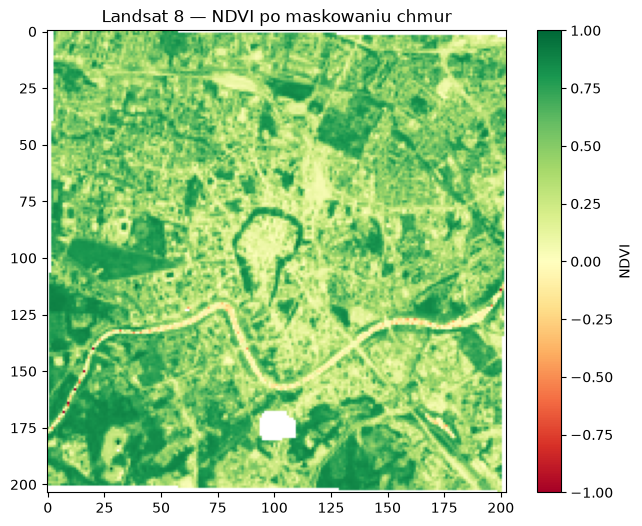

Średnie NDVI lokalnie: 0.4881607938101891


In [8]:
with rasterio.open(output_ndvi) as src:
    ndvi_local = src.read(1, masked=True)
    ndvi_local = np.ma.masked_equal(ndvi_local, -9999)
    profile = src.profile.copy()
    print("CRS:", src.crs)
    print("Rozdzielczość:", src.res)
    print("Rozmiar:", src.width, src.height)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(ndvi_local, cmap="RdYlGn", vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label="NDVI")
ax.set_title("Landsat 8 — NDVI po maskowaniu chmur")
plt.show()
print("Średnie NDVI lokalnie:", float(ndvi_local.mean()))

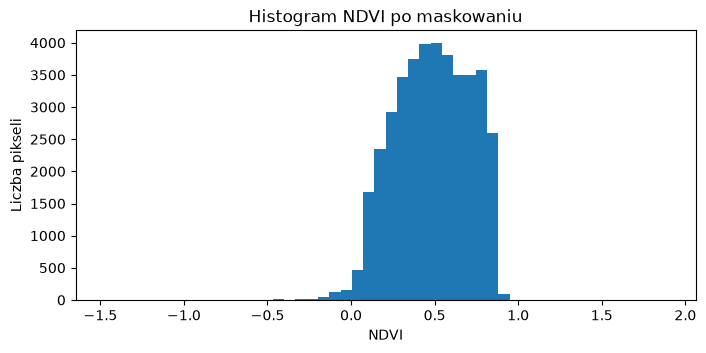

In [9]:
valid = ndvi_local.compressed()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(valid, bins=50)
ax.set_xlabel("NDVI")
ax.set_ylabel("Liczba pikseli")
ax.set_title("Histogram NDVI po maskowaniu")
plt.show()

## 9. Zadania dla studentów

- [ ] Zmień zakres dat i sprawdź liczbę scen.
- [ ] Zmień próg `CLOUD_COVER` i porównaj wybraną scenę.
- [ ] Zapisz ID i datę wybranej sceny. Sprawdź, czy to ten sam obraz co posiadany lokalnie Landsat 8.
- [ ] Porównaj RGB oraz NDVI przed i po maskowaniu.
- [ ] Zmodyfikuj maskę, aby wykluczyć również śnieg (bit 5). Jak zmienia się wynik?
- [ ] Porównaj NDVI Landsat 8 z wynikami Sentinel-2. Uwzględnij różnice dat i rozdzielczości.

### Ważne uwagi

- `CLOUD_COVER` jest właściwością **całej sceny**; nie zastępuje maskowania pikselowego.
- Pojedyncza scena może nadal zawierać znaczne luki po usunięciu chmur.
- Należy porównywać obrazy o zgodnym zasięgu, CRS i rozdzielczości; zwykłe porównanie średnich może być mylące.
- W tym ćwiczeniu pobieramy Landsata wyłącznie **z GEE**. Alternatywne źródła (np. STAC) mogą stanowić kolejny temat.

**Dokumentacja:** [GEE Landsat 8 C2 L2](https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LC08_C02_T1_L2), [USGS migracja C1 → C2](https://developers.google.com/earth-engine/landsat_c1_to_c2).